# 01 — Data audit and EDA
Prerequisite (terminal, from `02_code/`):
```
python -m src.prepare all
```
(download ≈ 200 MB from Zenodo 1188976, metadata, fixed splits, feature cache). Or set `RUN_PREPARE = True` below.
Outputs: `results/tables/` and `results/figures/eda_*.png` (template section 5.1).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
%matplotlib inline
print("project root:", ROOT)

project root: <repo>


In [2]:
RUN_PREPARE = False
if RUN_PREPARE:
    import subprocess
    subprocess.run([sys.executable, "-m", "src.prepare", "all"], cwd=ROOT, check=True)

In [3]:
import pandas as pd
from src import data, eda, features as feat, utils, analysis
pd.set_option("display.width", 200)
cfg = utils.load_config("m1")
meta = data.load_metadata()
splits = data.load_splits()
pd.DataFrame(data.verify_data(meta))

,check,passed,detail
0,data: exactly 1440 files,True,n=1440
1,"data: neutral=96, other emotions=192",True,"{'neutral': 96, 'calm': 192, 'happy': 192, 'sa..."
2,data: 60 files per actor (24 actors),True,[60]
3,data: 12 F / 12 M actors,True,"{'M': 12, 'F': 12}"
4,data: label map fixed (index = code-1) and saved,True,"{'neutral': 0, 'calm': 1, 'happy': 2, 'sad': 3..."


## WAV headers (sample rate, channels, bit depth)

In [4]:
hdr = eda.audit_files(meta, cfg["data"]["raw_dir"])
print(hdr["samplerate"].value_counts().to_dict(), hdr["channels"].value_counts().to_dict(), hdr["subtype"].value_counts().to_dict())
hdr["duration_s"].describe()

{48000: 1440} {1: 1435, 2: 5} {'PCM_16': 1440}


count    1440.000000
mean        3.700665
std         0.336676
min         2.936271
25%         3.470146
50%         3.670333
75%         3.870542
max         5.271937
Name: duration_s, dtype: float64

## Counts per emotion / actor / gender

,n,share
emotion,,
neutral,96,0.0667
calm,192,0.1333
happy,192,0.1333
sad,192,0.1333
angry,192,0.1333
fearful,192,0.1333
disgust,192,0.1333
surprised,192,0.1333


,actors,files
gender,,
F,12,720
M,12,720


intensity,1,2
emotion,,
neutral,96,0
calm,96,96
happy,96,96
sad,96,96
angry,96,96
fearful,96,96
disgust,96,96
surprised,96,96


gender,F,M
emotion,,
neutral,48,48
calm,96,96
happy,96,96
sad,96,96
angry,96,96
fearful,96,96
disgust,96,96
surprised,96,96


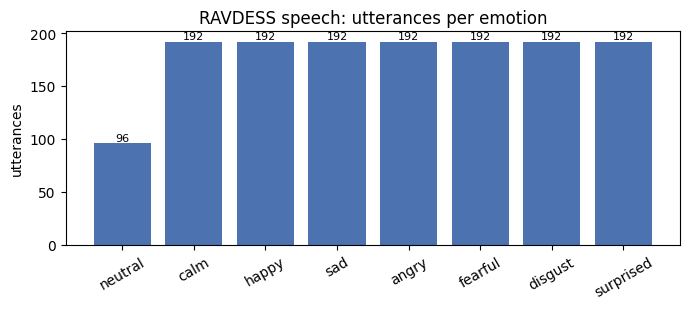

In [5]:
t = eda.count_tables(meta)
display(t["by_emotion"]); display(t["by_gender"]); display(t["emotion_x_intensity"]); display(t["emotion_x_gender"])
eda.plot_class_distribution(meta);

## Durations (raw vs. after silence trim)

,mean,median,std,min,max
raw_duration_s,3.700665,3.670333,0.336676,2.936271,5.271937
trimmed_duration_s,1.895870,1.792000,0.419813,1.152000,4.247937


orig sample rates: {48000: 1440}


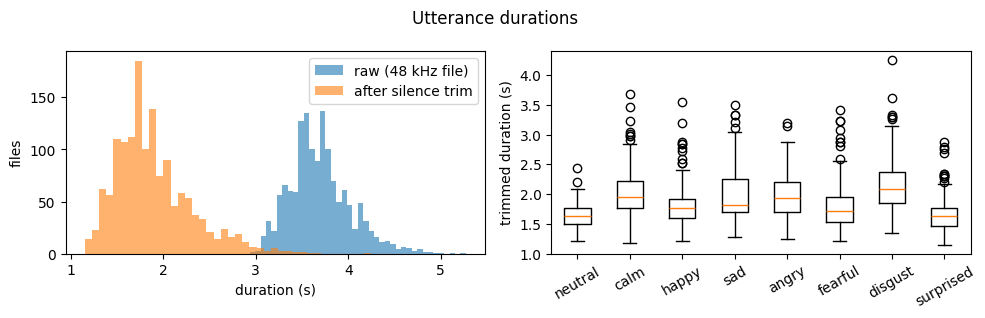

In [6]:
prep = pd.read_csv(feat.cache_dir(cfg) / "preprocess_info.csv")
display(eda.duration_stats(prep))
print("orig sample rates:", prep["orig_sr"].value_counts().to_dict())
eda.plot_durations(prep, meta);

## Log-mel spectrogram per emotion

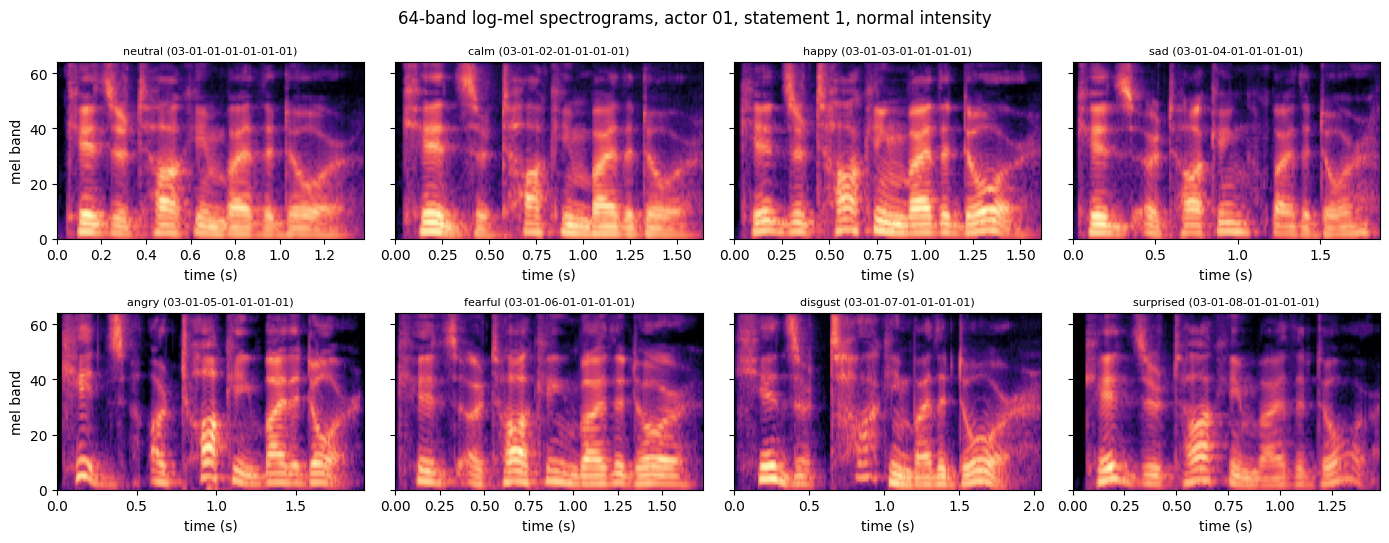

In [7]:
eda.plot_logmel_per_emotion(cfg, meta, actor=1);

## Acoustic descriptors (template 5.1.1 adapted to audio)
pyin F0 on 1,440 clips — a few minutes with all cores.

In [8]:
desc = eda.acoustic_descriptors(cfg, meta)
overall, by_emo = eda.descriptor_stats(desc)
display(overall.round(3)); display(by_emo.round(2))

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 32 concurrent workers.
[Parallel(n_jobs=-1)]: Done  98 tasks      | elapsed:   24.6s
[Parallel(n_jobs=-1)]: Done 301 tasks      | elapsed:   43.1s
[Parallel(n_jobs=-1)]: Done 584 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 949 tasks      | elapsed:  1.7min
[Parallel(n_jobs=-1)]: Done 1440 out of 1440 | elapsed:  2.4min finished


,mean,median,std,max,min
duration_s,1.896,1.792,0.420,4.248,1.152
rms_db_mean,-23.686,-23.097,3.878,-16.558,-44.407
rms_db_std,11.129,10.491,2.657,38.080,6.689
f0_mean_hz,225.384,215.529,93.670,594.743,77.029
f0_std_hz,38.824,32.074,25.060,159.043,1.029
f0_range_hz,123.611,103.269,78.252,470.971,2.943
voiced_fraction,0.723,0.752,0.163,0.985,0.000
spectral_centroid_hz,1744.482,1723.574,292.429,2764.894,774.845
zcr_mean,0.152,0.148,0.038,0.329,0.054


duration_s              rms_db_mean              rms_db_std              f0_mean_hz  ... f0_range_hz voiced_fraction              spectral_centroid_hz                  zcr_mean         \
                mean median   std        mean median   std       mean median   std       mean  ...         std            mean median   std                 mean   median     std     mean median   
emotion                                                                                        ...                                                                                                  
neutral         1.64   1.63  0.22      -22.18 -22.49  2.45      10.08   9.85  1.39     168.64  ...       45.43            0.85   0.89  0.09              1487.80  1490.95  218.73     0.13   0.12   
calm            2.04   1.95  0.42      -22.61 -21.88  3.71      10.49   9.91  2.60     162.37  ...       38.97            0.81   0.83  0.11              1575.05  1576.56  227.19     0.14   0.14   
happy           1.79   1.76  0.35      -22.75 -22.90  2.83      10.48  10.05  1.86     246.16  ...       70.17            0.78   0.80  0.12              1722.97  1702.14  256.33     0.14   0.14   
sad             1.98   1.82  0.46      -24.60 -23.76  4.68      11.77  10.63  3.72     208.28  ...       70.21            0.71   0.76  0.19              1658.52  1616.16  301.30     0.15   0.14   
angry           1.96   1.94  0.36      -24.80 -24.70  2.98      11.34  11.06  2.11     262.41  ...       67.11            0.68   0.71  0.15              1928.62  1918.58  269.00     0.17   0.17   
fearful         1.80   1.71  0.39      -23.98 -23.07  4.26      11.45  10.65  2.84     275.56  ...       73.54            0.73   0.77  0.15              1836.95  1803.69  289.78     0.16   0.15   
disgust         2.17   2.08  0.45      -25.43 -24.70  4.55      11.92  11.08  3.19     195.92  ...       78.84            0.63   0.66  0.18              1854.91  1846.33  264.63     0.17   0.17   
surprised       1.65   1.63  0.29      -22.39 -21.98  2.95      10.99  10.84  1.70     255.62  ...       90.71            0.65   0.68  0.15              1762.70  1746.24  246.72     0.15   0.15   

                 
            std  
emotion          
neutral    0.03  
calm       0.03  
happy      0.03  
sad        0.04  
angry      0.03  
fearful    0.04  
disgust    0.04  
surprised  0.03  

[8 rows x 27 columns]

## Association of descriptors with the emotion label
Target is nominal (8 classes) → η² (correlation ratio) and Kruskal–Wallis ε² instead of Pearson correlation.

,descriptor,eta_squared,kruskal_H,kruskal_p,epsilon_squared,n
4,f0_std_hz,0.2083,318.0866,0.0,0.2180,1435
5,f0_range_hz,0.2041,316.1439,0.0,0.2166,1435
7,spectral_centroid_hz,0.1942,280.3254,0.0,0.1909,1440
3,f0_mean_hz,0.1824,288.9775,0.0,0.1976,1435
6,voiced_fraction,0.1694,291.7038,0.0,0.1988,1440
0,duration_s,0.1680,289.9696,0.0,0.1976,1440
8,zcr_mean,0.1324,201.8086,0.0,0.1360,1440
1,rms_db_mean,0.0894,139.4502,0.0,0.0925,1440
2,rms_db_std,0.0490,91.4022,0.0,0.0589,1440


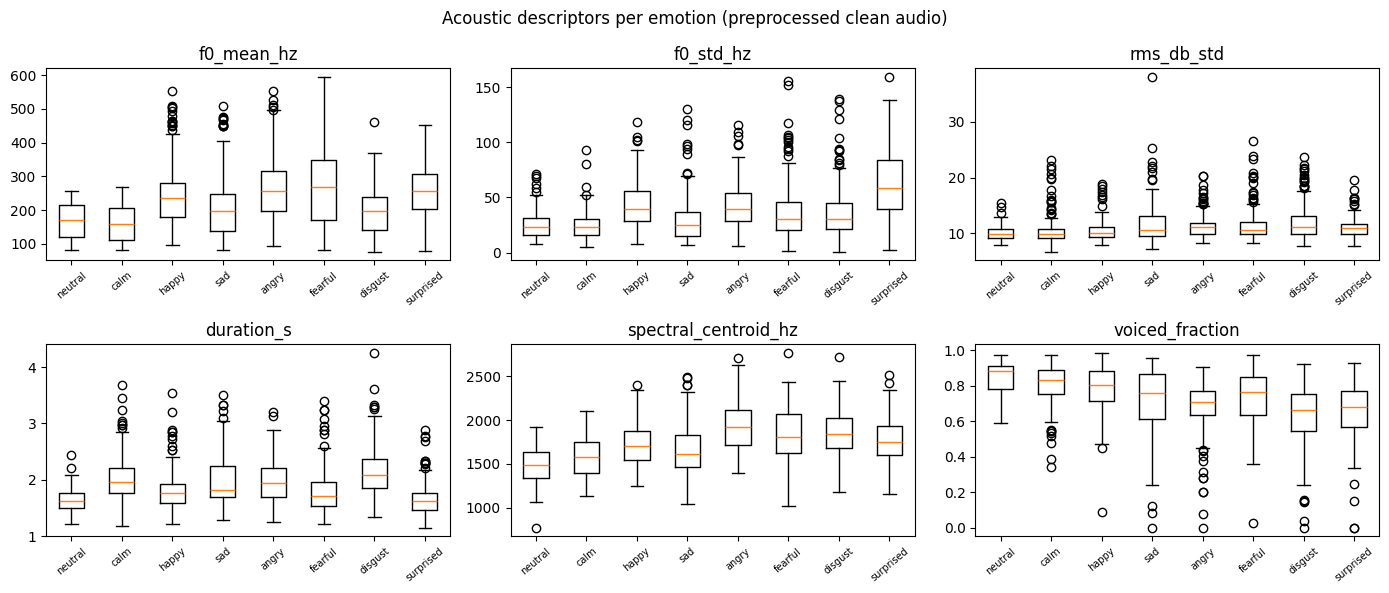

In [9]:
display(eda.descriptor_association(desc).round(4))
eda.plot_descriptor_boxplots(desc);

## Splits (fixed once, `splits/folds.json`)

In [10]:
g = dict(zip(meta.actor, meta.gender))
display(pd.DataFrame([{"fold": k, "actors": ", ".join(f"{a:02d}{g[a]}" for a in f)} for k, f in enumerate(splits["folds"]["folds"])]))
pd.DataFrame(data.verify_splits(meta, splits))

,fold,actors
0,0,"04F, 07M, 14F, 17M"
1,1,"11M, 15M, 18F, 20F"
2,2,"01M, 02F, 21M, 24F"
3,3,"06F, 08F, 09M, 19M"
4,4,"03M, 12F, 16F, 23M"
5,5,"05M, 10F, 13M, 22F"


,check,passed,detail
0,"folds: 6 folds x 4 actors, every actor exactly...",True,"[[4, 7, 14, 17], [11, 15, 18, 20], [1, 2, 21, ..."
1,folds: each fold 2 F + 2 M,True,"[['4F', '7M', '14F', '17M'], ['11M', '15M', '1..."
2,folds: train/val/test actors pairwise disjoint...,True,
3,folds: sizes 960/240/240 in every round,True,"[[960, 240, 240], [960, 240, 240], [960, 240, ..."
4,folds: every actor in test exactly once across...,True,
5,"random split: 960/240/240, utterances disjoint",True,
6,random split: actors ARE shared (leakage prese...,True,24/24 test actors also in train
7,random split: stratified by emotion (counts pe...,True,"{'train': [64, 128, 128, 128, 128, 128, 128, 1..."


## Trivial baselines (chance UAR = 12.5 %)

In [11]:
analysis.baseline_table(meta, splits)

test_acc            test_uar           test_macro_f1          
                    mean       std      mean       std          mean       std
baseline                                                                      
majority        0.133333  0.000000  0.125000  0.000000      0.029412  0.000000
prior_random    0.116667  0.012360  0.115234  0.013700      0.114206  0.012924
uniform_random  0.115278  0.014829  0.120443  0.015112      0.114413  0.013904